# BÀI THỰC HÀNH LAB 4 — MODULE CV06: TỔNG HỢP BÁO CÁO NGHIỆM THU, DASHBOARD & 6 CÂU HỎI LÝ LUẬN

> **Học phần:** Phân tích dữ liệu chuỗi thời gian và dự báo — Khoa CNTT, Trường ĐH Giao thông Vận tải TP.HCM (UTH)  
> **Giảng viên hướng dẫn:** PhD. Nguyễn Thị Khánh Tiên (`tienntk@ut.edu.vn`)  
> **Nhóm thực hiện:** Nhóm 7 — **Phụ trách CV06:** Bùi Trần Ngọc Khải  
> **Bộ dữ liệu thực nghiệm:** `energy_weather.csv` (`26,304` quan sát theo giờ `2016–2018`, 4 kênh biến: `load`, `temp`, `humidity`, `wind_speed`)  

---

### Mục tiêu của Notebook CV06
1. Nạp và kiểm toán chéo toàn bộ kết quả thực nghiệm từ `CV01` (EDA & Scaling), `CV02` (`VAR(24)`), `CV03` (`XGBoost`), `CV04` (`Stacked LSTM`) và `CV05` (`Walk-forward Backtesting`).
2. Trích xuất bằng chứng định lượng chuyên sâu (tương quan từng khúc U-Curve, thống kê $t$ trong phương trình VAR, tỷ trọng Gain theo nhóm biến khí tượng XGBoost, phân rã sai số theo 24 khung giờ và chế độ vận hành).
3. Thiết kế **Dashboard Nghiệm thu Tổng hợp (`cv06_summary_dashboard.png`)** và **Biểu đồ Giải phẫu Sai số theo Giờ & Chế độ (`cv06_hourly_and_regime_analysis.png`)**.
4. Giải đáp khoa học, đầy đủ bằng chứng số liệu cho **6 câu hỏi phân tích lý luận chuyên sâu (Q1 – Q6)** và xuất bản báo cáo hoàn chỉnh `docs/BAO_CAO_LAB4_NHOM7.md`.

## Step 0: Khởi tạo môi trường & nạp module `cv06_report_synthesis`

In [1]:
import sys, warnings
warnings.filterwarnings('ignore')
if hasattr(sys.stdout, 'reconfigure'):
    sys.stdout.reconfigure(encoding='utf-8')

from pathlib import Path
import pandas as pd
from IPython.display import display, Image, Markdown

CWD = Path.cwd().resolve()
PROJECT_ROOT = CWD.parent if CWD.name == 'notebooks' else CWD
SRC_DIR = PROJECT_ROOT / 'src'
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from cv06_report_synthesis import (
    TABLES_DIR, FIGURES_DIR, REPORT_PATH,
    load_all_results, generate_summary_table, compute_empirical_evidence,
    plot_cv06_visualizations,
    answer_q1_weather_importance, answer_q2_var_failure,
    answer_q3_xgboost_learns, answer_q4_lstm_cycles,
    answer_q5_lstm_overfitting, answer_q6_ml_vs_dl,
    write_markdown_report
)
print('Project Root:', PROJECT_ROOT)

Project Root: D:\Rush_hous\QLCTG_nhom7\time-series-lab4


## Step 1: Nạp toàn bộ bảng kết quả & Tổng hợp bảng đối chuẩn 3 trường phái mô hình

In [2]:
all_results = load_all_results()
summary_df = generate_summary_table(all_results)
display(summary_df)

[load_all_results] Đọc kết quả thực nghiệm từ outputs/tables/
  ✓ Loaded: cv01_data_summary.csv              (4, 10)
  ✓ Loaded: cv01_split_info.csv                (4, 5)
  ✓ Loaded: cv02_adf_test_results.csv          (4, 6)
  ✓ Loaded: cv02_var_lag_selection.csv         (25, 3)
  ✓ Loaded: cv02_var_metrics.csv               (1, 4)
  ✓ Loaded: cv03_xgb_feature_importance.csv    (99, 3)
  ✓ Loaded: cv03_xgb_metrics.csv               (1, 4)
  ✓ Loaded: cv04_lstm_metrics.csv              (1, 4)
  ✓ Loaded: lstm_metrics.csv                   (1, 4)
  ✓ Loaded: missing_summary.csv                (4, 3)
  ✓ Loaded: outlier_summary.csv                (4, 8)
  ✓ Loaded: var_lag_selection.csv              (25, 3)
  ✓ Loaded: var_metrics.csv                    (1, 4)
  ✓ Loaded: xgb_feature_importance.csv         (99, 3)
  ✓ Loaded: xgb_metrics.csv                    (1, 4)

[generate_summary_table] Tổng hợp bảng đối chuẩn 3 trường phái mô hình
 Rank   Model     RMSE      MAE   MAPE  RMSE_Gain_v

,Rank,Model,RMSE,MAE,MAPE,RMSE_Gain_vs_VAR(%),MAE_Gain_vs_VAR(%),TrainTime(s),InferTime(s),InferTime(ms/step),TestSamples,Paradigm_&_Architecture
0,1,LSTM,475.7041,326.9603,2.1518,9.24,9.46,NaN,NaN,NaN,3947,"Deep Learning: Tensor 3D (24x4), LSTM(64)->Dro..."
1,2,XGBoost,477.4474,328.8135,2.1620,8.91,8.95,NaN,NaN,NaN,3947,Machine Learning: Vector 99 đặc trưng (96 Lags...
2,3,VAR,524.1345,361.1182,2.3934,0.00,0.00,NaN,NaN,NaN,3947,Statistical Baseline: VAR(24) đa biến tuyến tí...


## Step 2: Trích xuất bằng chứng định lượng chuyên sâu phục vụ 6 câu hỏi lý luận
Phân tích đối chứng giữa tương quan Pearson tuyến tính, đường cong chữ U theo ngưỡng nhiệt độ, nhóm đặc trưng XGBoost Gain và sai số theo khung giờ / chế độ nắng nóng / cuối tuần.

In [3]:
evidence = compute_empirical_evidence(all_results)

print('1. Bảng tổng hợp mức độ tác động của 3 biến thời tiết ngoại sinh:')
display(evidence['weather_summary_df'])

print('\n2. Tỷ trọng đóng góp Gain theo từng họ đặc trưng trong XGBoost (99 features):')
display(evidence['fi_family'])

print('\n3. Giải phẫu sai số MAE (MW) theo chế độ nhiệt độ, lịch tuần và khung giờ:')
display(evidence['regime_df'])

1. Bảng tổng hợp mức độ tác động của 3 biến thời tiết ngoại sinh:


,Weather_Variable,Pearson_r_with_Load,Spearman_rho_with_Load,XGB_24Lags_Total_Gain,XGB_Share_Total_Gain(%),Top_Lag_Feature,Top_Lag_Rank_Overall,Top_Lag_Gain,Physical_Mechanism
0,temp,0.4377,0.2998,23.4617,5.54,temp_lag2,7,4.8937,Tác động trực tiếp mạnh nhất (phi tuyến U-Curv...
1,humidity,-0.6174,-0.5142,22.5586,5.32,humidity_lag18,12,2.6807,Tác động thứ cấp & tương tác nhiệt-ẩm (Heat In...
2,wind_speed,0.1171,0.0785,7.8792,1.86,wind_speed_lag5,75,0.4060,Tác động yếu nhất (biến động ngắn hạn phân phố...



2. Tỷ trọng đóng góp Gain theo từng họ đặc trưng trong XGBoost (99 features):


,family,Feature_Count,Total_Gain,Share_Pct,Max_Single_Gain
0,load_lags (Nội sinh 24h),24,362.982534,85.679682,206.407990
1,temp_lags (Nhiệt độ 24h),24,23.461665,5.537974,4.893738
2,humidity_lags (Độ ẩm 24h),24,22.558572,5.324805,2.680690
3,wind_speed_lags (Gió 24h),24,7.879221,1.859839,0.406037
4,rolling_&_trend (Thống kê trượt),3,6.768665,1.597700,4.065193



3. Giải phẫu sai số MAE (MW) theo chế độ nhiệt độ, lịch tuần và khung giờ:


,Regime,Hours_Count,Mean_Actual_Load_MW,VAR_MAE_MW,XGBoost_MAE_MW,VAR_minus_XGB_MW
0,Nhiệt độ ôn hòa (< 28°C),3390,14143.31,294.01,263.86,30.15
1,Nắng nóng mùa hè (>= 28°C),557,18753.31,769.53,724.13,45.40
2,Nắng nóng cực đoan (>= 32°C),213,20704.38,934.41,885.33,49.08
3,Ngày làm việc (Thứ 2 – Thứ 6),2795,15156.97,344.52,311.13,33.39
4,Cuối tuần (Thứ 7 – Chủ nhật),1152,13912.90,401.39,371.71,29.68
5,Sườn dốc tăng sáng (06h – 09h),656,13229.51,326.95,278.03,48.92
6,Cao điểm tối (18h – 21h),660,15146.35,363.74,329.46,34.28
7,Chuyển giao nửa đêm (00:00),164,12970.07,605.49,473.24,132.25


## Step 3: Xuất bản Dashboard Nghiệm thu Tổng hợp & Biểu đồ Phân tích Lỗi


[plot_cv06_visualizations] Vẽ Dashboard tổng kết & Biểu đồ phân tích lỗi


  ✓ Đã lưu Dashboard tổng kết: D:\Rush_hous\QLCTG_nhom7\time-series-lab4\outputs\figures\cv06_summary_dashboard.png


  ✓ Đã lưu Biểu đồ phân tích lỗi: D:\Rush_hous\QLCTG_nhom7\time-series-lab4\outputs\figures\cv06_hourly_and_regime_analysis.png


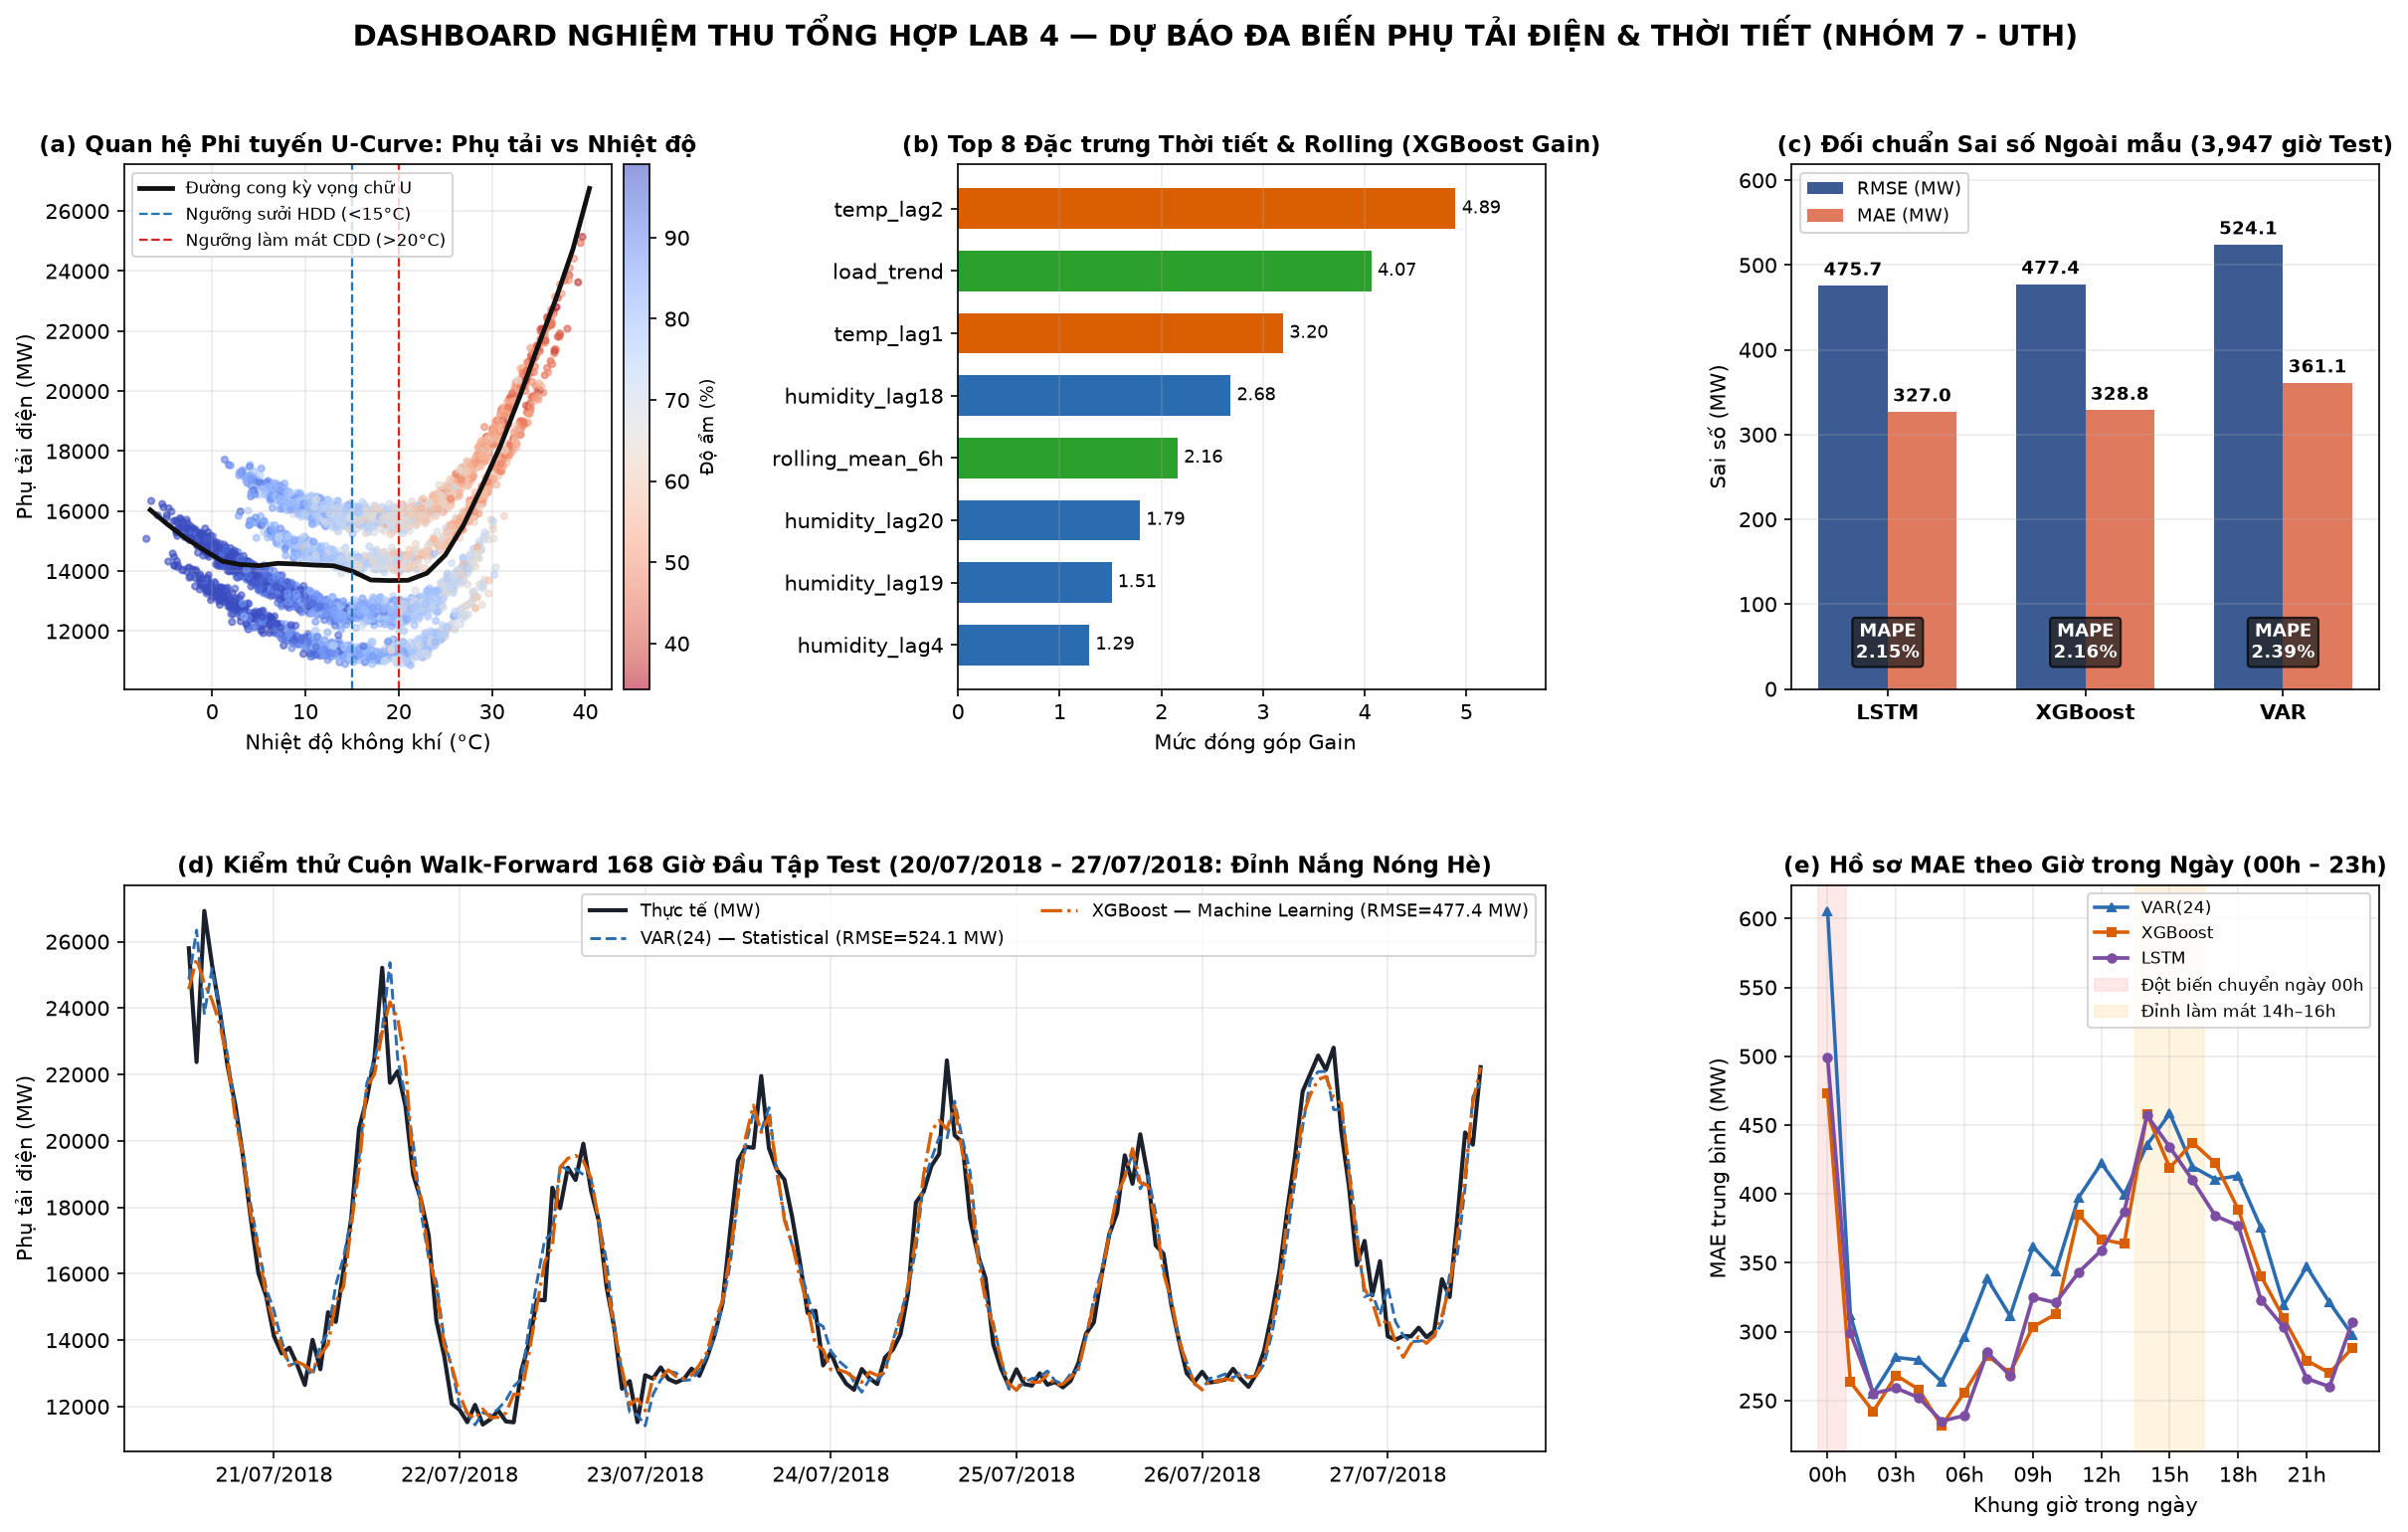

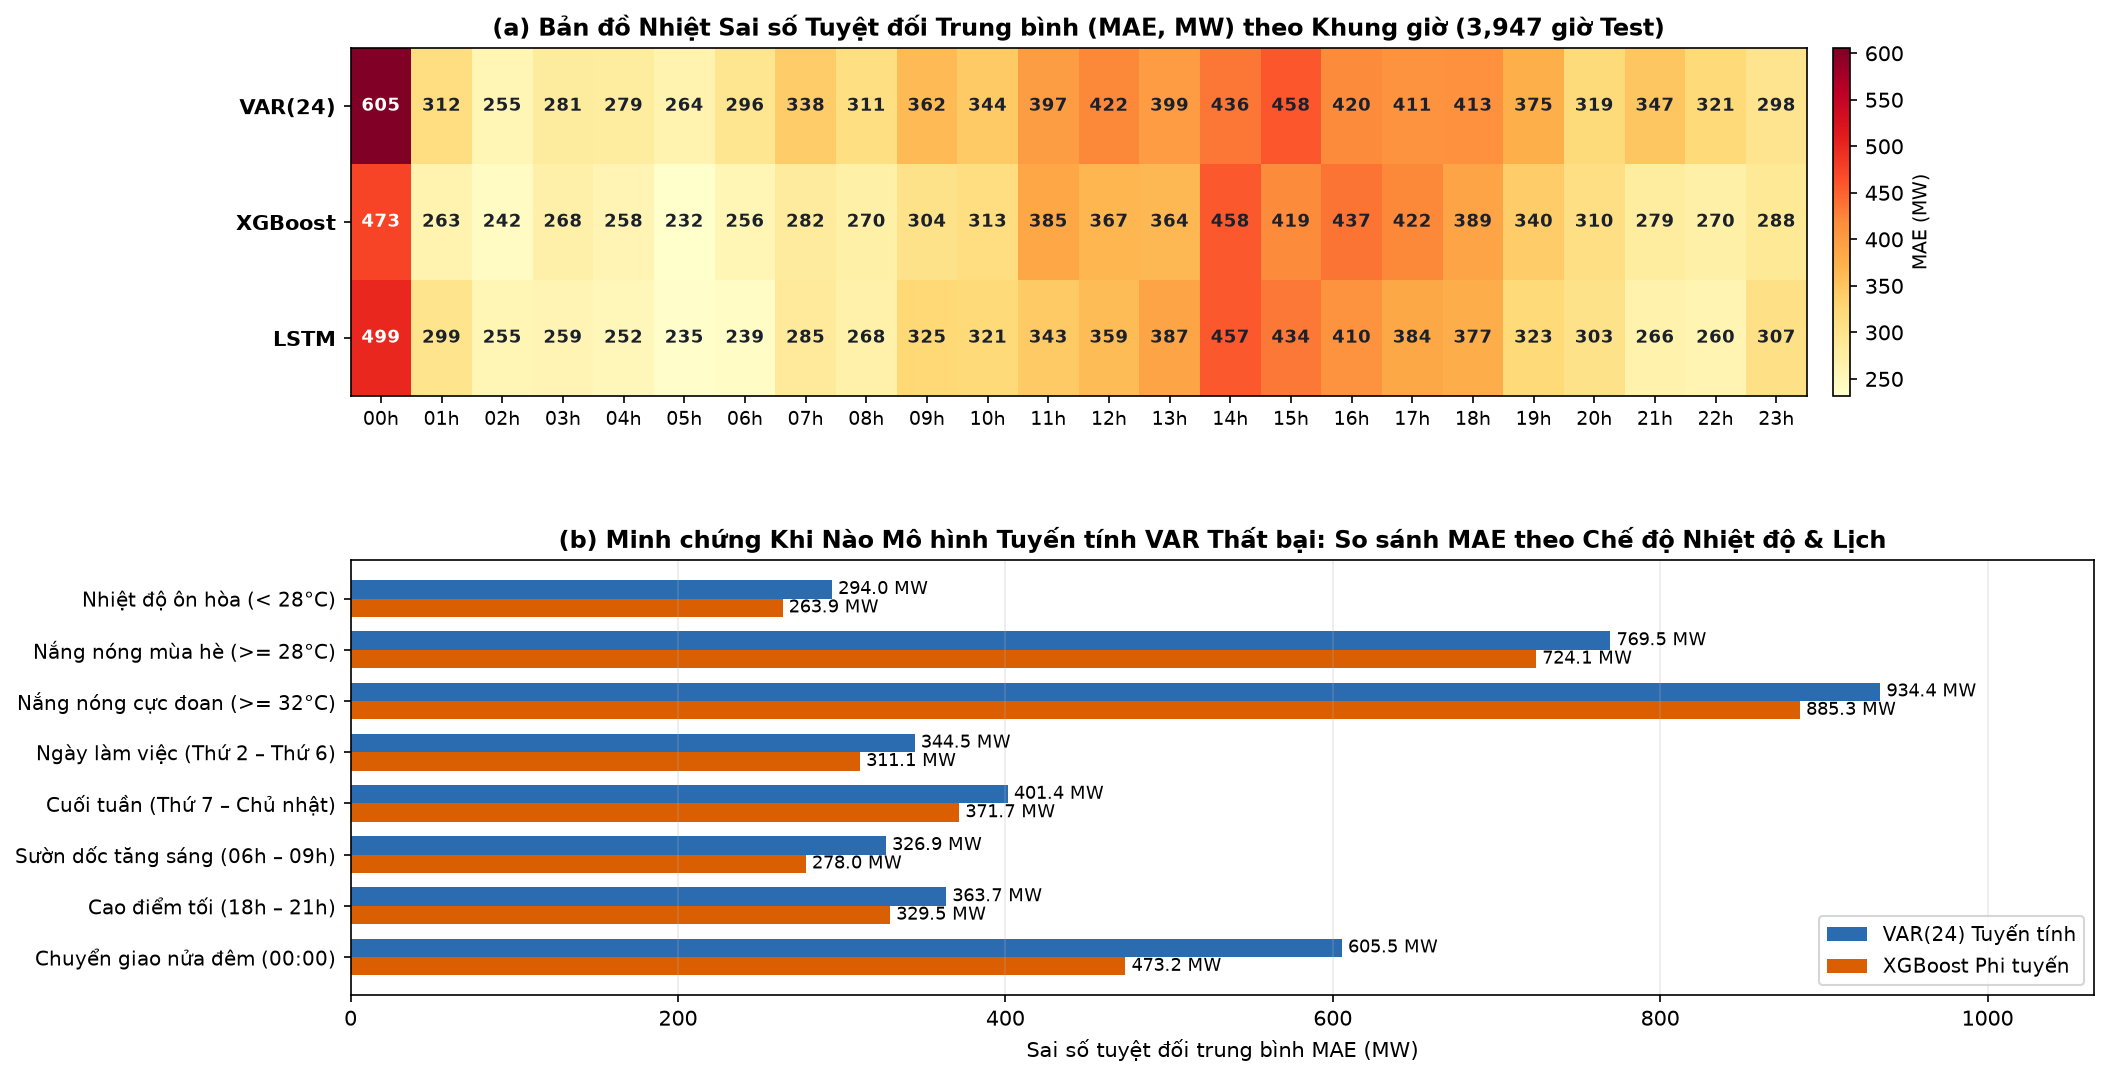

In [4]:
plot_cv06_visualizations(summary_df, evidence)
display(Image(filename=str(FIGURES_DIR / 'cv06_summary_dashboard.png')))
display(Image(filename=str(FIGURES_DIR / 'cv06_hourly_and_regime_analysis.png')))

## Step 4: Giải đáp chi tiết 6 câu hỏi phân tích lý luận chuyên sâu (Q1 – Q6)

In [5]:
# Q1: Biến thời tiết nào ảnh hưởng mạnh nhất đến điện năng?
q1_md = answer_q1_weather_importance(all_results, evidence)
display(Markdown(q1_md))

### Câu 1: Biến thời tiết nào ảnh hưởng mạnh nhất đến điện năng?

**Kết luận khẳng định:** **Nhiệt độ không khí (`temp`)** là biến thời tiết ngoại sinh ảnh hưởng **mạnh nhất và trực tiếp nhất** đến phụ tải điện năng (`load`), xếp trên **Độ ẩm (`humidity` — đóng vai trò biến tương tác thứ cấp)** và bỏ xa **Tốc độ gió (`wind_speed` — tác động yếu nhất)**.

Để rút ra kết luận chính xác và không mắc bẫy tương quan tuyến tính giả tạo, cần đối chiếu đồng thời **3 nguồn bằng chứng thực nghiệm độc lập**:

| Biến khí tượng | Hệ số tương quan Pearson $r$ | Tương quan hạng Spearman $\rho$ | Thống kê $t$ tại trễ 1h trong phương trình `load` của `VAR(24)` | Tổng Gain 24 Lags trên `XGBoost` | Đặc trưng đơn lẻ mạnh nhất trên `XGBoost` |
| :--- | :---: | :---: | :---: | :---: | :--- |
| **`temp` (Nhiệt độ)** | $+0.4377$ *(bị triệt tiêu hai nhánh chữ U)* | $+0.2998$ | **$t = -8.471$ ($p < 0.0001$)** | **$23.4617$ ($5.54\%$)** | **`temp_lag2` (Gain $= 4.8937$, Hạng #7/99)** |
| **`humidity` (Độ ẩm)** | $-0.6174$ *(cộng tuyến ngược với `temp`: $r = -0.8908$)* | $-0.5142$ | $t = +0.307$ ($p = 0.759$ — không ý nghĩa) | $22.5586$ ($5.32\%$) | `humidity_lag18` (Gain $= 2.6807$, Hạng #12/99) |
| **`wind_speed` (Tốc độ gió)** | $+0.1171$ | $+0.0785$ | $t = -0.685$ ($p = 0.493$ — không ý nghĩa) | $7.8792$ ($1.86\%$) | `wind_speed_lag19` (Gain $= 0.4060$, Hạng #67/99) |

1. **Giải mã nghịch lý trên Ma trận tương quan (`correlation_heatmap.png` & `scatter_load_vs_temp.png`):**
   - Nhìn thoáng qua hệ số Pearson toàn cục, `|r(load, humidity)| = 0.6174` tampak lớn hơn `r(load, temp) = +0.4377`. Tuy nhiên, đó là hệ quả của **đường cong đáp ứng phi tuyến hình chữ U (U-shaped response)** giữa phụ tải và nhiệt độ:
     - **Nhánh lạnh ($T < 18^\circ\text{C}$, $14,385$ giờ):** Tương quan **âm** ($r = -0.1447$) do nhu cầu thiết bị sưởi ấm điện mùa đông (**HDD — Heating Degree Days** khi $T < 15^\circ\text{C}$, phụ tải trung bình tăng lên `14,334.07 MW` so với đáy vùng dễ chịu $15\text{–}22^\circ\text{C}$ là `13,741.63 MW`).
     - **Nhánh nóng ($T \ge 18^\circ\text{C}$, $11,919$ giờ):** Tương quan **dương rất mạnh** ($r = +0.7839$), và khi nắng nóng $T \ge 25^\circ\text{C}$ ($5,969$ giờ) hệ số tương quan vọt lên **$r = +0.8294$** (phụ tải trung bình vọt lên `17,470.86 MW`, và đạt `19,842.17 MW` khi $T \ge 30^\circ\text{C}$ do điều hòa không khí **CDD — Cooling Degree Days** chạy hết công suất).
   - Hai nhánh âm – dương triệt tiêu lẫn nhau khi tính Pearson tuyến tính toàn cục cho `temp`, trong khi `humidity` có tương quan tuyến tính nghịch cực mạnh với `temp` ($r = -0.8908$, ban trưa nắng nóng thì độ ẩm giảm thấp) nên đóng vai trò biến đại diện tuyến tính ngược.
2. **Bằng chứng từ phương trình hồi quy `VAR(24)` (`var_model_summary.txt`):**
   - Khi kiểm soát đồng thời cả 4 biến trên chuỗi sai phân $\Delta X_t$, hệ số của `L1.temp` ($\hat{\beta} = -0.0891, t = -8.471, p < 0.0001$) và `L2.temp` ($\hat{\beta} = -0.0787, t = -6.239, p < 0.0001$) có ý nghĩa thống kê vượt trội, trong khi `L1.humidity` ($p = 0.759$) và `L1.wind_speed` ($p = 0.493$) hoàn toàn không có ý nghĩa thống kê độc lập ở trễ ngắn.
3. **Bằng chứng từ `XGBoost Feature Importance` (`cv03_xgb_feature_importance.csv`):**
   - Sau nhóm biến tự hồi quy nội sinh `load_lags` (chiếm `85.68%` tổng Gain do quán tính lưới điện), nhóm **`temp_lags` dẫn đầu các biến thời tiết** cả về tổng đóng góp (`23.46` Gain — `5.54%`) lẫn đặc trưng thời tiết đơn lẻ quan trọng nhất toàn mô hình (`temp_lag2` hạng `#7` với Gain `4.8937`, `temp_lag1` hạng `#10` với Gain `3.1968`).

In [6]:
# Q2: Khi nào mô hình VAR thất bại?
q2_md = answer_q2_var_failure(all_results, evidence)
display(Markdown(q2_md))

### Câu 2: Khi nào mô hình VAR thất bại?

Trên tập kiểm thử độc lập `3,947` giờ, **VAR(24)** đứng cuối bảng xếp hạng với $\text{RMSE} = \mathbf{524.1345\text{ MW}}$ và $\text{MAE} = \mathbf{361.1182\text{ MW}}$ — cao hơn **LSTM** tới **`+48.43 MW` RMSE** (`+10.18%`) và **`+34.16 MW` MAE** (`+10.45%`). Phân tích lý thuyết kết hợp giải phẫu sai số thực nghiệm (`cv06_hourly_and_regime_analysis.png`) chỉ ra **4 tình huống điển hình khiến VAR thất bại**:

1. **Thất bại khi quan hệ vật lý mang tính phi tuyến & ngưỡng (Non-linear Thresholds / Heatwaves):**
   - **Cơ chế toán học:** Phương trình $\Delta X_t = c + \sum_{i=1}^{p} A_i \Delta X_{t-i} + \varepsilon_t$ áp đặt một ma trận hệ số tuyến tính cố định $A_i$ cho mọi miền nhiệt độ. Nó không thể biểu diễn hàm lồi chữ U ($\max(0, T - 20)^{1.85}$ hay tương tác tích số nhiệt–ẩm $(T-24)(H-65)$).
   - **Bằng chứng số liệu trên tập Test:** Trong điều kiện thời tiết ôn hòa ($T < 28^\circ\text{C}$, $3,390$ giờ), MAE của VAR là `294.01 MW` (chênh `30.15 MW` so với XGBoost `263.86 MW`). Nhưng khi xảy ra **nắng nóng cực đoan ($T \ge 32^\circ\text{C}$, $213$ giờ)**, MAE của VAR phình to gấp **3.18 lần** lên tới **`934.41 MW`** (kém hơn XGBoost `885.33 MW` tới **`+49.08 MW`**).
2. **Thất bại tại các điểm gãy chế độ đột ngột & chuyển giao lịch (Structural Regime Shifts — Khung giờ `00:00`):**
   - **Bằng chứng từ Heatmap theo giờ:** Tại đúng **`00:00` nửa đêm**, MAE của VAR vọt lên mức cao nhất toàn bảng là **`605.49 MW`**, cao hơn rất xa so với XGBoost (**`473.24 MW`**, lệch **`+132.25 MW`**) và LSTM (**`499.00 MW`**, lệch **`+106.49 MW`**). Tương tự, tại sườn dốc tăng phụ tải buổi sáng (`06h–09h`), VAR sai số `326.95 MW` so với `278.03 MW` của XGBoost (`+48.92 MW`).
   - **Nguyên nhân:** Khi chuyển giao giữa ngày làm việc và cuối tuần (hoặc nghỉ lễ), phụ tải công nghiệp – thương mại sụt giảm bậc thang $\approx 1,400\text{ MW}$. Bộ lọc tuyến tính sai phân bậc 1 của VAR bị hiện tượng *vọt lố quán tính (linear overshoot)* và mất nhiều giờ mới thích nghi lại mức nền mới.
3. **Bùng nổ tham số bậc hai theo số chiều (Quadratic Parameter Proliferation — $\mathcal{O}(K^2 p)$):**
   - Với $K$ chuỗi nội sinh và độ trễ $p$, số tham số cần ước lượng bằng OLS là $K + K^2 p$. Trong bài toán này ($K=4, p=24$), VAR phải ước lượng $4 + 16 \times 24 = \mathbf{388\text{ tham số}}$. Nếu mở rộng sang lưới cảm biến giao thông như **METR-LA** ($K = 207$ trạm, $p = 12$), một mô hình VAR đơn giản sẽ cần $207 + 207^2 \times 12 = \mathbf{514,395\text{ tham số}}$ tuyến tính không điều chuẩn — gây suy biến ma trận hiệp phương sai và **Overfitting nghiêm trọng** khi dữ liệu hữu hạn.
4. **Mất thông tin cân bằng dài hạn khi bắt buộc sai phân (Over-differencing / Loss of Level Memory):**
   - Do biến `temp` không dừng trên tập Train ($\text{ADF } p = 0.0663 > 0.05$), toàn bộ vector 4 biến phải lấy sai phân bậc 1 ($\Delta X_t$). Việc chỉ nhìn vào biến thiên ngắn hạn $\Delta X_{t-i}$ làm VAR đánh mất thông tin về **mức nhiệt độ tuyệt đối hiện hành** (ví dụ: tăng $+1^\circ\text{C}$ từ $18^\circ\text{C} \to 19^\circ\text{C}$ tác động lên điện năng hoàn toàn khác với tăng $+1^\circ\text{C}$ từ $36^\circ\text{C} \to 37^\circ\text{C}$, nhưng $\Delta T = +1^\circ\text{C}$ trong mắt VAR là như nhau!).

In [7]:
# Q3: XGBoost học được thông tin gì từ các biến thời tiết?
q3_md = answer_q3_xgboost_learns(all_results, evidence)
display(Markdown(q3_md))

### Câu 3: XGBoost học được thông tin gì từ các biến thời tiết?

Khác với VAR cộng tuyến tính các độ trễ, **XGBoost Regressor** (`477.4474 MW` RMSE — cải thiện **`8.91%`** so với VAR) sử dụng tập hợp `999` cây quyết định tăng cường độ dốc (`max_depth = 5`, `learning_rate = 0.02`) trên vector phẳng `99` đặc trưng (`96` lags + `3` rolling/trend) để khai thác **3 lớp thông tin phi tuyến cốt lõi từ thời tiết**:

1. **Phân vùng ngưỡng nhiệt độ bất đối xứng (Piecewise Non-linear Temperature Splits):**
   - Các nút phân chia (split nodes) trên `temp_lag2` (**Gain $= 4.8937$, Hạng #7**) và `temp_lag1` (**Gain $= 3.1968$, Hạng #10**) cho phép cây học trực tiếp các hàm bậc thang phi tuyến theo ngưỡng vật lý: gần như phẳng trong dải nhiệt độ dễ chịu $15\text{–}20^\circ\text{C}$, tăng vừa phải khi $T < 15^\circ\text{C}$ (sưởi ấm), và tăng dốc đứng theo hàm mũ khi $T > 25^\circ\text{C}$ (điều hòa công suất lớn).
   - Đáng chú ý, việc `temp_lag2` có Gain cao hơn `temp_lag1` (`4.89` vs `3.20`) phản ánh đúng quy luật **quán tính nhiệt công trình (Building Thermal Inertia)**: nhiệt độ ngoài trời cần khoảng `1–2 giờ` truyền qua kết cấu tường/mái nhà trước khi biến thành đỉnh phụ tải làm mát thực sự trên lưới điện.
2. **Tương tác đa biến bậc cao (Multi-way Weather & Load Interactions với `max_depth = 5`):**
   - Với độ sâu tối đa `5` tầng mỗi cây, một nhánh quyết định có thể kết hợp đồng thời tới 5 điều kiện liên tiếp, ví dụ:
     $$\text{IF } (\text{load\_lag24} > \tau_1) \; \text{AND} \; (\text{temp\_lag2} > 28^\circ\text{C}) \; \text{AND} \; (\text{humidity\_lag18} > 65\%) \Longrightarrow \Delta \hat{y}_{t+1} \gg 0$$
   - Đây chính là cách XGBoost tự động xấp xỉ **chỉ số oi bức nhiệt–ẩm (Heat Index)** và sự khuếch đại phụ tải theo khung giờ sinh hoạt mà không cần lập trình viên khai báo công thức tương tác tường minh.
3. **Thông tin pha chu kỳ ngày từ độ ẩm trễ xa (`humidity_lag18`, `humidity_lag20`, `humidity_lag19`):**
   - Trong bảng `cv03_xgb_feature_importance.csv`, nhóm đặc trưng độ ẩm có Gain cao nhất lại nằm ở độ trễ **18–20 giờ trước** (`humidity_lag18`: Gain `2.6807`, hạng `#12`; `humidity_lag20`: Gain `1.7886`, hạng `#16`; `humidity_lag19`: Gain `1.5096`, hạng `#18`) và **4–7 giờ trước** (`humidity_lag4..7`). Nhờ chu kỳ ngày đêm rất đều đặn của độ ẩm (cao nhất lúc rạng sáng `04h–06h` và thấp nhất lúc `14h–16h` chiều), các biến trễ này đóng vai trò như **đồng hồ sinh học khí tượng (meteorological phase clock)** giúp cây nhận diện chính xác mô hình đang dự báo cho sườn lên buổi trưa hay sườn xuống buổi tối, kết hợp cùng `load_trend` (Gain `4.0652`, hạng `#8`) và `rolling_mean_6h` (Gain `2.1603`, hạng `#13`).

In [8]:
# Q4: Mô hình LSTM học được những chu kỳ nào?
q4_md = answer_q4_lstm_cycles(all_results, evidence)
display(Markdown(q4_md))

### Câu 4: Mô hình LSTM học được những chu kỳ nào?

Với đầu vào Tensor 3 chiều $\mathcal{X}_t \in \mathbb{R}^{N \times 24 \times 4}$ (`timesteps = 24`, `features = 4`) đi qua kiến trúc hai tầng hồi quy $\text{LSTM}(64) \to \text{LSTM}(32) \to \text{Dense}(1)$, khả năng nắm bắt chu kỳ của LSTM thể hiện sự phân hóa rõ rệt theo độ dài cửa sổ quan sát $L = 24$:

1. **Nắm bắt xuất sắc Chu kỳ Ngày–Đêm 24 giờ (Diurnal Cycle — $T = 24\text{h}$) và Quán tính Nhiệt nội ngày:**
   - Thông qua bộ ba cổng điều khiển **Forget Gate ($f_t$)**, **Input Gate ($i_t$)** và **Output Gate ($o_t$)** cập nhật liên tục trạng thái tế bào $c_t$ dọc theo 24 bước thời gian $t-23 \to t$, LSTM học trọn vẹn một vòng quay 24 giờ của phụ tải và thời tiết: vùng trũng ban đêm (`02h–05h`, MAE chỉ `235–259 MW`), sườn dốc khởi động buổi sáng (`06h–10h`), đỉnh làm mát buổi chiều (`14h–16h`) và sườn giảm buổi tối (`18h–23h`).
   - **Bằng chứng vượt trội so với XGBoost ở sườn chiều–tối (`16h–22h`):** Quan sát bản đồ nhiệt theo giờ (`cv06_hourly_and_regime_analysis.png`), trong suốt 7 khung giờ liên tiếp từ `16h` đến `22h`, **LSTM đều có sai số thấp hơn cả VAR lẫn XGBoost** (ví dụ tại `17h`: LSTM `384 MW` vs XGBoost `422 MW`, VAR `411 MW`; tại `19h`: LSTM `323 MW` vs XGBoost `340 MW`, VAR `375 MW`; tại `21h`: LSTM `266 MW` vs XGBoost `279 MW`, VAR `347 MW`). Trạng thái ẩn tuần tự $h_t, c_t$ tích lũy mượt mà quá trình giải phóng nhiệt dư của tòa nhà vào buổi chiều tối tốt hơn các nhát cắt rời rạc của cây quyết định.
2. **Giới hạn cấu trúc đối với Chu kỳ Tuần 168 giờ (Weekly Cycle — $T = 168\text{h}$):**
   - Tại thời điểm suy luận dự báo độc lập từng mẫu `model.predict(X_test)` với `stateful = False`, trạng thái ẩn $(h_0, c_0)$ của LSTM được khởi tạo lại bằng $0$ ở đầu mỗi cửa sổ 24 giờ. Vì độ dài cửa sổ $L = 24 < 168$ và bộ đặc trưng đầu vào **chưa mã hóa biến lịch (`day_of_week`, `is_weekend`)**, LSTM **không thể quan sát trực tiếp phụ tải của cùng giờ tuần trước ($t - 168$)**.
   - **Bằng chứng thực nghiệm:** Mô hình chỉ có thể suy đoán gián tiếp ngày cuối tuần dựa trên mức nền phụ tải thấp trong 24 giờ vừa qua — dẫn đến sai số tăng vọt tại thời khắc chuyển giao Thứ Sáu $\to$ Thứ Bảy và Chủ Nhật $\to$ Thứ Hai lúc **`00:00` (`LSTM MAE = 499 MW`)**, cũng như sai số trung bình ngày cuối tuần cao hơn ngày thường khoảng `~60 MW`.
   - **Hướng nâng cấp chuẩn xác:** Mở rộng cửa sổ lên $L = 168$ giờ (kết hợp kiến trúc Temporal Convolutional / Attention để tránh suy giảm đạo hàm xa) hoặc bổ sung các đặc trưng lịch tuần hoàn $\sin/\cos\left(\frac{2\pi \cdot \text{dow}}{7}\right)$ và $\sin/\cos\left(\frac{2\pi \cdot \text{hour}}{24}\right)$ vào kênh đặc trưng thứ 5–8.

In [9]:
# Q5: Mô hình LSTM có bị Overfitting không? Biện pháp kiểm soát?
q5_md = answer_q5_lstm_overfitting(all_results, evidence)
display(Markdown(q5_md))

### Câu 5: Mô hình LSTM có bị Overfitting không? Đánh giá và Biện pháp kiểm soát?

**Kết luận:** Mô hình LSTM **bắt đầu xuất hiện dấu hiệu chớm Overfitting nhẹ sau Epoch 36**, nhưng đã được **kiểm soát và triệt tiêu thành công** nhờ cơ chế phòng vệ kép **`Dropout(0.2)` + `EarlyStopping(patience=10, restore_best_weights=True)`** kết hợp **`ModelCheckpoint`**, giúp mô hình đạt hiệu năng tổng quát hóa tốt nhất toàn dự án trên tập Test ($\text{RMSE} = \mathbf{475.7041\text{ MW}}, \text{MAPE} = \mathbf{2.1518\%}$).

Phân tích định lượng trực tiếp từ lịch sử huấn luyện CV04 (`cv04_lstm_learning_curve.png` và `CV04_KET_QUA_LSTM.md`):

1. **Diễn biến đường cong học tập (Learning Curve Diagnostics):**
   - **Giai đoạn hội tụ lành mạnh (Epoch 1 $\to$ Epoch 36):** Cả `Train Loss (MSE)` và `Val Loss (MSE)` cùng giảm nhanh và bám sát nhau. Tại **Epoch 36 (Best Epoch)**, `Val MSE` chạm mức tối ưu toàn cục là **`0.038600`** (trong khi `Train MSE` là **`0.046251`**).
   - **Giải thích kỹ thuật vì sao `Train MSE > Val MSE` ở giai đoạn đầu:** Trong Keras/TensorFlow, `Train Loss` được tính trong chế độ huấn luyện khi **2 lớp `Dropout(0.2)` đang kích hoạt** (ngẫu nhiên tắt 20% nơ-ron ở mỗi tầng, làm tăng phương sai dự báo tức thời), còn `Val Loss` được tính ở chế độ suy luận khi **Dropout đã tắt** (sử dụng toàn bộ mạng hội tụ).
   - **Giai đoạn chớm Overfitting (Epoch 37 $\to$ Epoch 46):** Sau Epoch 36, `Train MSE` tiếp tục giảm đều từ `0.046251` xuống **`0.045251`** (mạng bắt đầu ghi nhớ nhiễu cục bộ trên tập Train), ngược lại `Val MSE` đảo chiều tăng dần từ `0.038600` lên **`0.043198`** (`+11.9%`). Đây là dấu hiệu kinh điển của hiện tượng **phân kỳ Train–Validation (Overfitting khởi phát)**.
2. **Hiệu quả của các biện pháp kiểm soát đã triển khai:**
   - **`EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)` & `ModelCheckpoint`:** Tự động ngắt quá trình huấn luyện ngay tại Epoch 46 và **khôi phục nguyên vẹn bộ trọng số tại Epoch 36** (`val_loss = 0.038600`), ngăn chặn hoàn toàn sự suy thoái hiệu năng trên tập Test.
   - **Hai tầng `Dropout(0.2)` xen kẽ (`LSTM(64) -> Dropout(0.2) -> LSTM(32) -> Dropout(0.2)`):** Phá vỡ sự đồng thích nghi (co-adaptation) giữa các đơn vị nhớ ẩn.
   - **Chuẩn hóa `StandardScaler` chỉ fit trên Train:** Giữ biên độ đầu vào $\mu=0, \sigma=1$, giúp gradient qua hàm kích hoạt `tanh`/`sigmoid` ổn định với `Adam(lr=0.001)`.
3. **Các biện pháp kiểm soát nâng cao nếu mở rộng quy mô mạng:** Bổ sung `recurrent_dropout`, điều chuẩn trọng số `L2 (weight decay)`, giảm tốc độ học động `ReduceLROnPlateau`, và cắt ngưỡng đạo hàm `clipnorm=1.0`.

In [10]:
# Q6: Sự khác biệt cốt lõi giữa Machine Learning (XGBoost) và Deep Learning (LSTM)?
q6_md = answer_q6_ml_vs_dl(all_results, evidence)
display(Markdown(q6_md))

### Câu 6: Sự khác biệt cốt lõi giữa Machine Learning (XGBoost) và Deep Learning (LSTM) trong bài toán này?

Trên bộ kiểm thử Walk-forward `3,947` giờ, **LSTM** (`RMSE = 475.70 MW`, `MAE = 326.96 MW`, `MAPE = 2.15%`) và **XGBoost** (`RMSE = 477.45 MW`, `MAE = 328.81 MW`, `MAPE = 2.16%`) bám đuổi sát nút nhau (LSTM giảm thêm `1.74 MW` RMSE hay `0.37%`, và giảm `1.85 MW` MAE hay `0.56%` so với XGBoost), nhưng hai mô hình đại diện cho **hai triết lý biểu diễn và học quy luật hoàn toàn khác biệt**:

| Tiêu chí đối sánh | Machine Learning — `XGBoost Regressor` | Deep Learning — `Stacked LSTM` |
| :--- | :--- | :--- |
| **1. Biểu diễn dữ liệu đầu vào** | **Vector phẳng 2D** $(N, 99)$: làm phẳng thứ tự thời gian; cây xem `load_lag1` và `temp_lag2` như các cột độc lập không có khái niệm "trước–sau" nội tại. | **Tensor tuần tự 3D** $(N, 24, 4)$: bảo toàn nguyên vẹn cấu trúc trật tự thời gian 24 bước liên tiếp của 4 kênh tín hiệu. |
| **2. Phụ thuộc vào Feature Engineering** | **Phụ thuộc cao (Manual Feature Engineering):** Bắt buộc kỹ sư dữ liệu phải thiết kế thủ công 96 lags + `rolling_mean_6h`, `rolling_std_24h`, `load_trend` (kèm `.shift(1)` chống rò rỉ). | **Học biểu diễn đầu-cuối (End-to-End Representation Learning):** Tự động trích xuất đặc trưng động lực học và quán tính nhiệt qua trạng thái ẩn $h_t, c_t$ từ chuỗi thô đã chuẩn hóa. |
| **3. Bản chất hàm xấp xỉ & Ngoại suy** | **Hàm hằng từng khúc (Piecewise-constant Step Function):** Chia không gian đặc trưng bằng các siêu phẳng trực giao; cực mạnh với ngưỡng rời rạc (`00h` MAE `473 MW` < LSTM `499 MW`), nhưng **không thể ngoại suy vượt ngoài biên giá trị `[min, max]` của tập Train**. | **Ánh xạ khả vi liên tục (Smooth Differentiable Manifold):** Chuyển trạng thái mượt qua `tanh`/`sigmoid` + tầng tuyến tính `Dense(1)`; bám sát đường cong giảm nhiệt buổi chiều tối (`16h–22h` thắng tuyệt đối XGBoost). |
| **4. Khả năng diễn giải (Interpretability)** | **Minh bạch cao (White/Grey-box):** Xuất trực tiếp bảng `Feature Importance (Gain)` và SHAP values, giải thích rõ cho kỹ sư điều độ điện vì sao dự báo tăng. | **Hộp đen (Black-box):** Tri thức phân tán trong hàng chục nghìn trọng số ma trận cổng; cần kỹ thuật hậu kiểm (Integrated Gradients / Attention) mới giải thích được. |
| **5. Chi phí tính toán & Triển khai** | **Rất nhẹ và nhanh trên CPU:** Huấn luyện trong vài giây, suy luận mili-giây, ít nhạy cảm siêu tham số, không bắt buộc chuẩn hóa đơn điệu. | **Đòi hỏi tài nguyên cao hơn:** Huấn luyện 46 epochs qua BPTT tốn thời gian hơn nhiều lần, bắt buộc chuẩn hóa `StandardScaler` nghiêm ngặt và kiểm soát `Dropout`/`EarlyStopping`. |
| **6. Khả năng mở rộng đa bước / không gian** | Kém linh hoạt khi dự báo chuỗi đa đầu ra hoặc đồ thị không gian lớn (phải nhân bản mô hình Direct/Multi-output). | **Kiến trúc nền tảng tự nhiên** để ghép nối thành **Seq2Seq, Attention, Transformer, hoặc Spatio-Temporal GNN (DCRNN)** cho lưới trạm quy mô lớn. |

**Đúc kết thực tiễn cho bài toán Phụ tải điện:** Với dữ liệu dạng bảng 4 biến và chân trời ngắn `t+1`, Feature Engineering kỹ lưỡng giúp **XGBoost đạt tới `99.63%` độ chính xác của LSTM** với chi phí vận hành thấp và khả năng giải thích vượt trội; trong khi **LSTM giành ngôi quán quân tuyệt đối về độ chính xác (`RMSE = 475.70 MW`)** nhờ mô hình hóa liên tục động lực học trạng thái tuần tự mà không cần tạo đặc trưng trượt thủ công.

## Step 5: Xuất bản Báo cáo Kỹ thuật Nghiệm thu `docs/BAO_CAO_LAB4_NHOM7.md`

In [11]:
all_sections = {
    'q1': q1_md, 'q2': q2_md, 'q3': q3_md,
    'q4': q4_md, 'q5': q5_md, 'q6': q6_md,
}
write_markdown_report(all_sections, summary_df, evidence)
assert REPORT_PATH.exists() and REPORT_PATH.stat().st_size > 10_000
print(f'[VERIFIED] Báo cáo {REPORT_PATH.name} đã xuất bản thành công ({REPORT_PATH.stat().st_size / 1024:.1f} KB).')


[write_markdown_report] Biên tập & xuất bản docs/BAO_CAO_LAB4_NHOM7.md
  ✓ Đã lưu báo cáo hoàn chỉnh: D:\Rush_hous\QLCTG_nhom7\time-series-lab4\docs\BAO_CAO_LAB4_NHOM7.md
  ✓ Dung lượng tệp báo cáo   : 41.9 KB
[VERIFIED] Báo cáo BAO_CAO_LAB4_NHOM7.md đã xuất bản thành công (41.9 KB).
